In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

data = {
    'Student': ['A','B','C','D','E','F','G','H','I','J',
                'K','L','M','N','O','P','Q','R','S','T'],

    'Marks': [45, 50, 52, 48, 55, 60, 58, 62, 65, 59,
              61, 57, 63, 56, 54, 51, 49, 95, 100, 5]
}

df = pd.DataFrame(data)

print(df)


   Student  Marks
0        A     45
1        B     50
2        C     52
3        D     48
4        E     55
5        F     60
6        G     58
7        H     62
8        I     65
9        J     59
10       K     61
11       L     57
12       M     63
13       N     56
14       O     54
15       P     51
16       Q     49
17       R     95
18       S    100
19       T      5


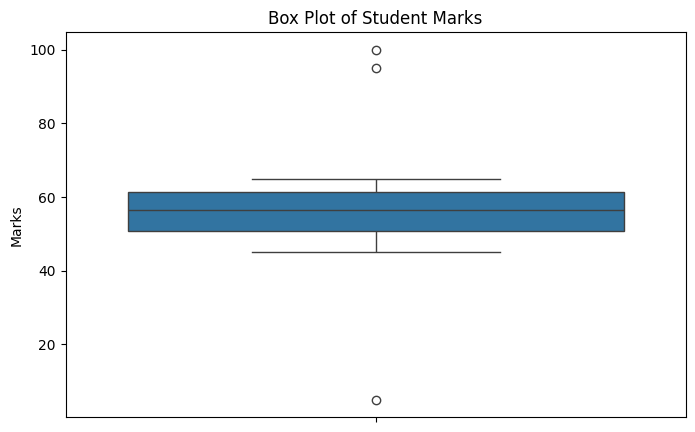

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Marks'])

plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")

plt.show()


In [19]:
Q1 = df['Marks'].quantile(0.25)
Q3 = df['Marks'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)



Q1 = 50.75
Q3 = 61.25


In [20]:
IQR = Q3 - Q1

print("IQR =", IQR)


IQR = 10.5


In [21]:
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)


Lower Limit = 35.0
Upper Limit = 77.0


In [22]:
outliers_iqr = df[
    (df['Marks'] < lower_limit) |
    (df['Marks'] > upper_limit)
]

print("Outliers detected using IQR:")
print(outliers_iqr)

Outliers detected using IQR:
   Student  Marks
17       R     95
18       S    100
19       T      5


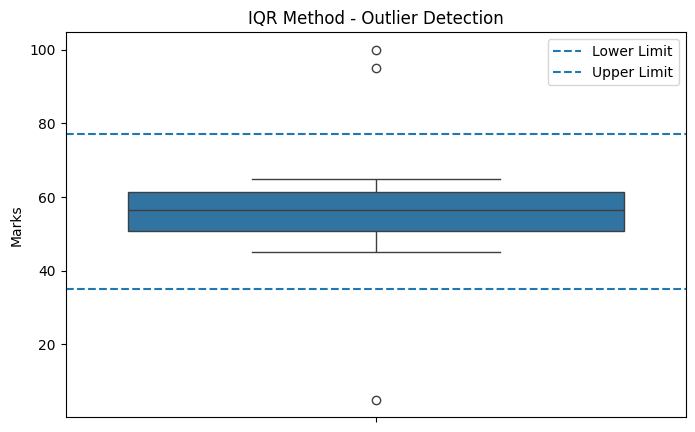

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Marks'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")
plt.legend()

plt.show()


In [24]:
df['Marks_IQR_Capped'] = df['Marks'].clip(lower=lower_limit,upper=upper_limit)

print(df[['Marks', 'Marks_IQR_Capped']])



    Marks  Marks_IQR_Capped
0      45                45
1      50                50
2      52                52
3      48                48
4      55                55
5      60                60
6      58                58
7      62                62
8      65                65
9      59                59
10     61                61
11     57                57
12     63                63
13     56                56
14     54                54
15     51                51
16     49                49
17     95                77
18    100                77
19      5                35


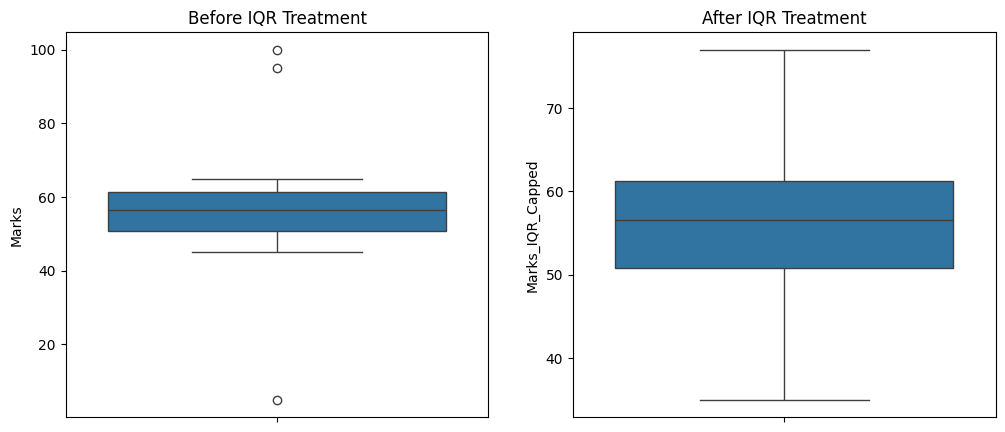

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Marks'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.show()



In [27]:
z_outliers = df[abs(df['Z_score']) > 3]

print("Outliers detected using Z-score:")
print(z_outliers)


df['Z_Outlier'] = abs(df['Z_score']) > 3

print(df[['Marks', 'Z_score', 'Z_Outlier']])


Outliers detected using Z-score:
Empty DataFrame
Columns: [Student, Marks, Marks_IQR_Capped, Z_score]
Index: []
    Marks   Z_score  Z_Outlier
0      45 -0.676200      False
1      50 -0.400200      False
2      52 -0.289800      False
3      48 -0.510600      False
4      55 -0.124200      False
5      60  0.151800      False
6      58  0.041400      False
7      62  0.262200      False
8      65  0.427800      False
9      59  0.096600      False
10     61  0.207000      False
11     57 -0.013800      False
12     63  0.317400      False
13     56 -0.069000      False
14     54 -0.179400      False
15     51 -0.345000      False
16     49 -0.455400      False
17     95  2.083800      False
18    100  2.359799      False
19      5 -2.884199      False


In [28]:
mean = df['Marks'].mean()
std = df['Marks'].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)



Lower Z-score limit = 1.4902946847626737
Upper Z-score limit = 113.00970531523733


In [29]:
df['Marks_Z_Capped'] = df['Marks'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print(df[['Marks', 'Marks_Z_Capped']])


    Marks  Marks_Z_Capped
0      45              45
1      50              50
2      52              52
3      48              48
4      55              55
5      60              60
6      58              58
7      62              62
8      65              65
9      59              59
10     61              61
11     57              57
12     63              63
13     56              56
14     54              54
15     51              51
16     49              49
17     95              95
18    100             100
19      5               5


    Marks  Marks_IQR_Capped  Marks_Z_Capped
0      45                45              45
1      50                50              50
2      52                52              52
3      48                48              48
4      55                55              55
5      60                60              60
6      58                58              58
7      62                62              62
8      65                65              65
9      59                59              59
10     61                61              61
11     57                57              57
12     63                63              63
13     56                56              56
14     54                54              54
15     51                51              51
16     49                49              49
17     95                77              95
18    100                77             100
19      5                35               5


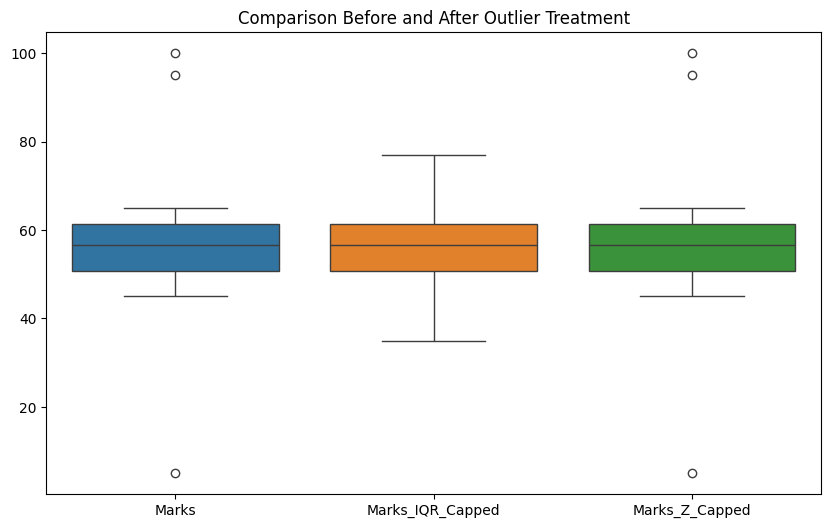

In [30]:
print(df[['Marks',
          'Marks_IQR_Capped',
          'Marks_Z_Capped']])


plt.figure(figsize=(10, 6))

sns.boxplot(data=df[
    ['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']
])

plt.title("Comparison Before and After Outlier Treatment")

plt.show()
